# Analyse univariée et bivariée — Maladie rénale chronique (CKD)

**Objectif :** décrire les variables du jeu de données, comparer les patients classés `ckd` et `notckd`, puis repérer les associations statistiques.


1. Exécutez les cellules dans l'ordre, de haut en bas.
2. Les résultats décrivent des **associations** dans ce jeu de données ; ils ne prouvent pas à eux seuls une causalité.

## 1. Importer les bibliothèques

In [16]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

## 2. Charger et vérifier les données

Si le fichier n'est pas trouvé, vérifiez son emplacement et modifiez `fichier_csv` pour indiquer son chemin exact.

In [17]:
fichier_csv = Path("..") / "data" / "kidney_clean.csv"

if not fichier_csv.exists():
    raise FileNotFoundError(
        f"Impossible de trouver {fichier_csv.resolve()}\n"
        "Lancer le notebook depuis le dossier notebooks/ du projet."
    )

df = pd.read_csv(fichier_csv)

In [18]:
print("Types de variables :")
display(df.dtypes.to_frame("type"))
print("\nValeurs manquantes par variable :")
display(df.isna().sum().sort_values(ascending=False).to_frame("valeurs_manquantes"))

Types de variables :


,type
id,int64
age,float64
bp,float64
sg,float64
al,float64
su,float64
rbc,str
pc,str
pcc,str
ba,str



Valeurs manquantes par variable :


,valeurs_manquantes
rbc,152
rc,131
wc,106
pot,90
sod,88
pcv,71
pc,65
hemo,52
su,49
sg,47


## 3. Préparer les variables

La liste ci-dessous correspond aux colonnes attendues dans le jeu CKD. Le code ne conserve que celles qui sont réellement présentes.

In [19]:
num_vars_attendues = [
    "age", "bp", "sg", "al", "su", "bgr", "bu", "sc",
    "sod", "pot", "hemo", "pcv", "wc", "rc"
]
cat_vars_attendues = [
    "htn", "dm", "cad", "appet", "pe", "ane",
    "pcc", "ba", "pc", "rbc", "classification"
]

num_vars = [c for c in num_vars_attendues if c in df.columns]
cat_vars = [c for c in cat_vars_attendues if c in df.columns]

# Convertir les variables quantitatives en nombres lorsque c'est possible.
for col in num_vars:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Harmoniser la variable de classification si elle existe.
if "classification" in df.columns:
    df["classification"] = (
        df["classification"].astype("string").str.strip().str.lower()
    )
    print("Répartition de classification :")
    display(df["classification"].value_counts(dropna=False).to_frame("effectif"))

print("Variables quantitatives disponibles :", num_vars)
print("Variables qualitatives disponibles :", cat_vars)

Répartition de classification :


,effectif
classification,
ckd,250
notckd,150


Variables quantitatives disponibles : ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']
Variables qualitatives disponibles : ['htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'pcc', 'ba', 'pc', 'rbc', 'classification']


## 4. Analyse univariée — variables quantitatives

On calcule les effectifs valides, les valeurs manquantes, la moyenne, l'écart-type, la médiane, les quartiles, l'étendue et l'asymétrie.

In [20]:
lignes = []
for col in num_vars:
    s = df[col].dropna()
    lignes.append({
        "Variable": col,
        "N_valides": int(s.count()),
        "N_manquants": int(df[col].isna().sum()),
        "%_manquants": round(df[col].isna().mean() * 100, 2),
        "Moyenne": s.mean(),
        "Ecart_type": s.std(),
        "Mediane": s.median(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "Min": s.min(),
        "Max": s.max(),
        "Skewness": s.skew()
    })

resume_num = pd.DataFrame(lignes).set_index("Variable").round(3)
display(resume_num)

,N_valides,N_manquants,%_manquants,Moyenne,Ecart_type,Mediane,Q1,Q3,IQR,Min,Max,Skewness
Variable,,,,,,,,,,,,
age,391,9,2.25,51.483,17.170,55.00,42.00,64.50,22.50,2.000,90.000,-0.668
bp,388,12,3.00,76.469,13.684,80.00,70.00,80.00,10.00,50.000,180.000,1.605
sg,353,47,11.75,1.017,0.006,1.02,1.01,1.02,0.01,1.005,1.025,-0.172
al,354,46,11.50,1.017,1.353,0.00,0.00,2.00,2.00,0.000,5.000,0.998
su,351,49,12.25,0.450,1.099,0.00,0.00,0.00,0.00,0.000,5.000,2.464
bgr,356,44,11.00,148.037,79.282,121.00,99.00,163.00,64.00,22.000,490.000,2.011
bu,381,19,4.75,57.426,50.503,42.00,27.00,66.00,39.00,1.500,391.000,2.634
sc,383,17,4.25,3.072,5.741,1.30,0.90,2.80,1.90,0.400,76.000,7.510
sod,312,88,22.00,137.955,7.184,138.00,135.00,142.00,7.00,104.000,163.000,-0.981


### Visualisations des variables quantitatives

Les histogrammes aident à voir la forme des distributions. Les valeurs extrêmes peuvent étirer l'échelle.

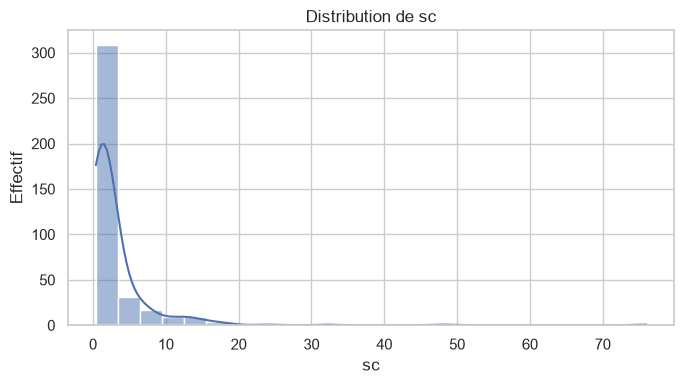

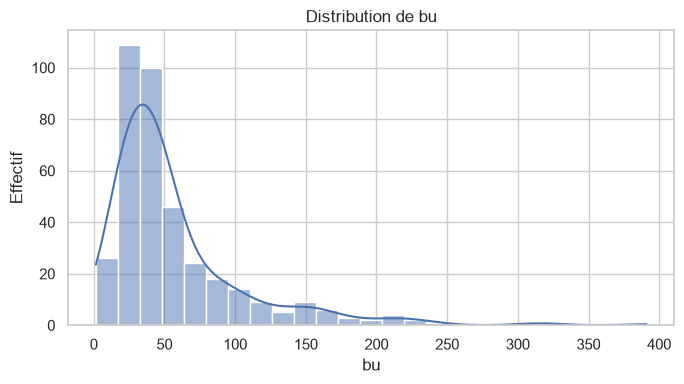

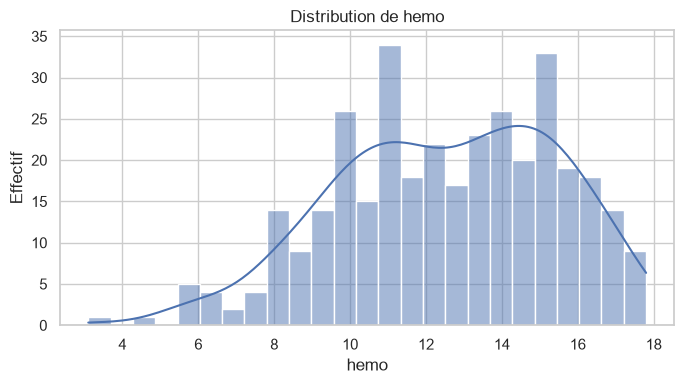

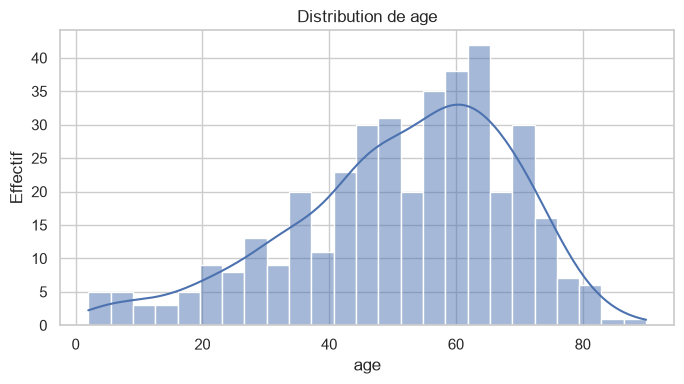

In [21]:
variables_a_tracer = [c for c in ["sc", "bu", "hemo", "age"] if c in num_vars]
for col in variables_a_tracer:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True, bins=25)
    plt.title(f"Distribution de {col}")
    plt.xlabel(col)
    plt.ylabel("Effectif")
    plt.tight_layout()
    plt.show()

## 5. Analyse univariée — variables qualitatives

Les tableaux présentent les effectifs et pourcentages, en incluant les valeurs manquantes.

In [22]:
for col in cat_vars:
    frequences = df[col].value_counts(dropna=False)
    tableau = pd.DataFrame({
        "Effectif": frequences,
        "Pourcentage (%)": (frequences / len(df) * 100).round(2)
    })
    print(f"\nVariable : {col}")
    display(tableau)


Variable : htn


,Effectif,Pourcentage (%)
htn,,
no,251,62.75
yes,147,36.75
NaN,2,0.50



Variable : dm


,Effectif,Pourcentage (%)
dm,,
no,261,65.25
yes,137,34.25
NaN,2,0.50



Variable : cad


...

,Effectif,Pourcentage (%)
pc,,
normal,259,64.75
abnormal,76,19.00
NaN,65,16.25



Variable : rbc


,Effectif,Pourcentage (%)
rbc,,
normal,201,50.25
NaN,152,38.00
abnormal,47,11.75



Variable : classification


,Effectif,Pourcentage (%)
classification,,
ckd,250,62.5
notckd,150,37.5


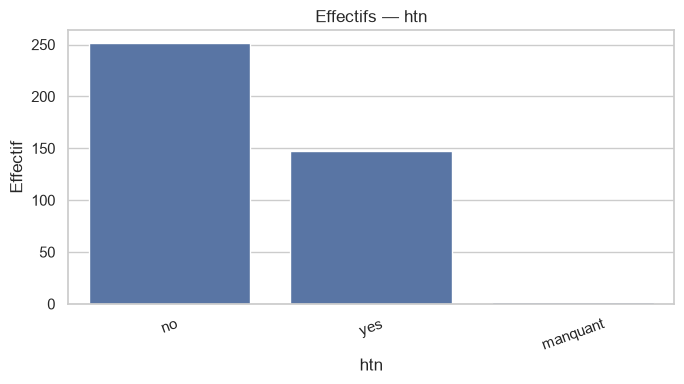

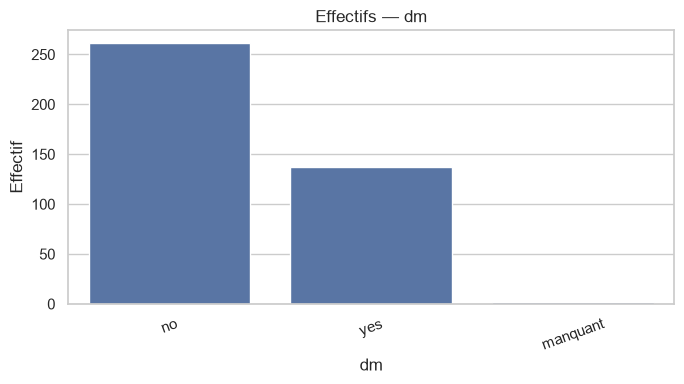

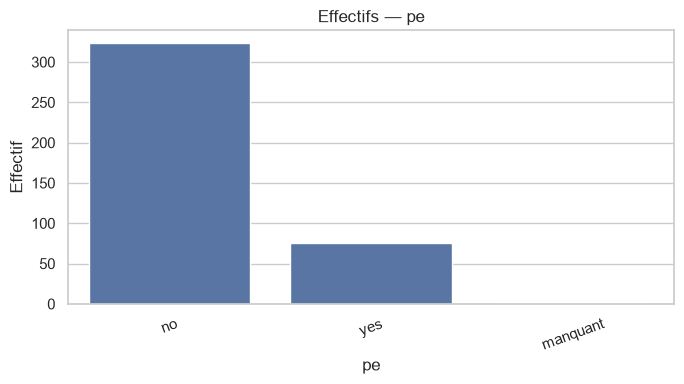

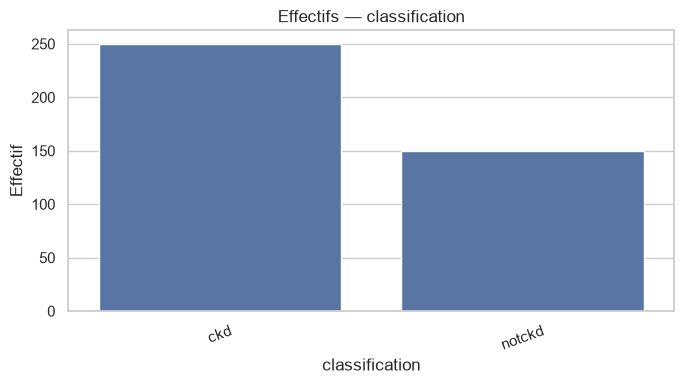

In [23]:
variables_cat_a_tracer = [c for c in ["htn", "dm", "pe", "classification"] if c in cat_vars]
for col in variables_cat_a_tracer:
    plt.figure(figsize=(7, 4))
    ordre = df[col].astype("string").fillna("manquant").value_counts().index
    sns.countplot(
        x=df[col].astype("string").fillna("manquant"),
        order=ordre
    )
    plt.title(f"Effectifs — {col}")
    plt.xlabel(col)
    plt.ylabel("Effectif")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## 6. Analyse bivariée — variables quantitatives selon la classification

Pour chaque variable, on compare les groupes `ckd` et `notckd`. Le test de Welch compare les moyennes sans supposer des variances égales ; le test de Mann–Whitney compare les rangs/distributions. Les deux tests ont des hypothèses différentes.

In [24]:
if "classification" not in df.columns:
    raise KeyError("La colonne 'classification' est nécessaire pour l'analyse bivariée.")

groupes_valides = set(df["classification"].dropna().unique())
print("Classes observées :", groupes_valides)

if not {"ckd", "notckd"}.issubset(groupes_valides):
    print("Attention : les classes ne sont pas exactement 'ckd' et 'notckd'. Vérifiez les valeurs ci-dessus.")

Classes observées : {'ckd', 'notckd'}


In [25]:
resultats_num = []
for col in num_vars:
    g_ckd = df.loc[df["classification"] == "ckd", col].dropna()
    g_not = df.loc[df["classification"] == "notckd", col].dropna()

    if len(g_ckd) < 2 or len(g_not) < 2:
        continue

    welch = stats.ttest_ind(g_ckd, g_not, equal_var=False, nan_policy="omit")
    mw = stats.mannwhitneyu(g_ckd, g_not, alternative="two-sided")

    resultats_num.append({
        "Variable": col,
        "N_CKD": len(g_ckd),
        "Moyenne_CKD": g_ckd.mean(),
        "Mediane_CKD": g_ckd.median(),
        "N_notCKD": len(g_not),
        "Moyenne_notCKD": g_not.mean(),
        "Mediane_notCKD": g_not.median(),
        "p_Welch": welch.pvalue,
        "p_Mann_Whitney": mw.pvalue
    })

comparaison_num = pd.DataFrame(resultats_num).set_index("Variable")
display(comparaison_num.round(5))

,N_CKD,Moyenne_CKD,Mediane_CKD,N_notCKD,Moyenne_notCKD,Mediane_notCKD,p_Welch,p_Mann_Whitney
Variable,,,,,,,,
age,242,54.54132,59.000,149,46.51678,46.00,0.00000,0.00000
bp,240,79.62500,80.000,148,71.35135,70.00,0.00000,0.00000
sg,208,1.01392,1.015,145,1.02241,1.02,0.00000,0.00000
al,209,1.72249,2.000,145,0.00000,0.00,0.00000,0.00000
su,206,0.76699,0.000,145,0.00000,0.00,0.00000,0.00000
bgr,212,175.41981,143.500,144,107.72222,107.50,0.00000,0.00000
bu,237,72.38903,53.000,144,32.79861,33.00,0.00000,0.00000
sc,238,4.41492,2.250,145,0.86897,0.90,0.00000,0.00000
sod,167,134.67665,136.000,145,141.73103,141.00,0.00000,0.00000


### Comparaisons graphiques

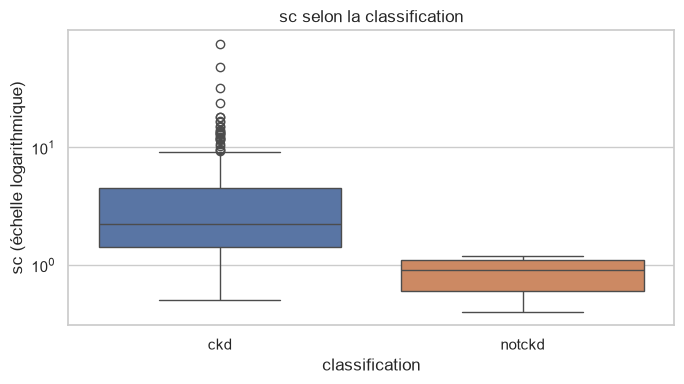

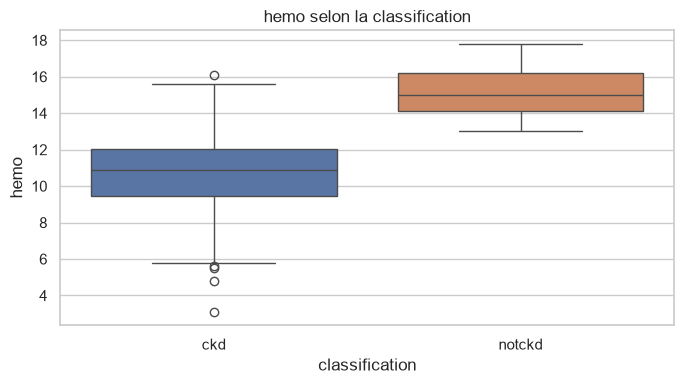

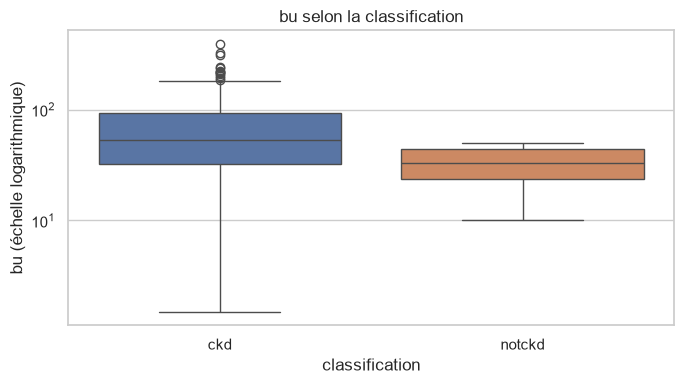

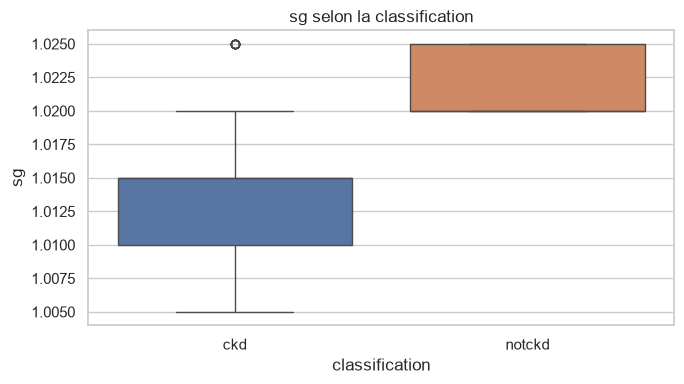

In [26]:
variables_boxplot = [c for c in ["sc", "hemo", "bu", "sg"] if c in num_vars]
for col in variables_boxplot:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="classification", y=col, hue="classification", legend=False)
    if col in ["sc", "bu"] and (df[col].dropna() > 0).all():
        plt.yscale("log")
        plt.ylabel(f"{col} (échelle logarithmique)")
    else:
        plt.ylabel(col)
    plt.title(f"{col} selon la classification")
    plt.tight_layout()
    plt.show()

## 7. Analyse bivariée — variables qualitatives

On construit des tableaux croisés et on applique le test du chi-deux. Le test ignore les observations manquantes dans les tableaux croisés. Si les effectifs théoriques sont faibles, l'interprétation du chi-deux doit être prudente ; pour un tableau 2×2, le test exact de Fisher peut être envisagé.

In [27]:
cat_explicatives = [c for c in [
    "htn", "dm", "cad", "appet", "pe", "ane", "pcc", "ba", "pc", "rbc"
] if c in df.columns]

resultats_cat = []
for col in cat_explicatives:
    ct = pd.crosstab(df[col], df["classification"])
    ct_test = ct.loc[ct.sum(axis=1) > 0, ct.sum(axis=0) > 0]

    print(f"\nTableau croisé : {col} × classification")
    display(ct)

    if ct_test.shape[0] >= 2 and ct_test.shape[1] >= 2:
        chi2, p, ddl, attendus = stats.chi2_contingency(ct_test)
        resultats_cat.append({
            "Variable": col,
            "Chi2": chi2,
            "ddl": ddl,
            "p_value": p,
            "Effectif_attendu_min": attendus.min()
        })
    else:
        print("Test non calculé : le tableau n'a pas au moins deux lignes et deux colonnes.")

comparaison_cat = pd.DataFrame(resultats_cat).set_index("Variable")
display(comparaison_cat.round(6))


Tableau croisé : htn × classification


classification,ckd,notckd
htn,,
no,103,148
yes,147,0



Tableau croisé : dm × classification


classification,ckd,notckd
dm,,
no,113,148
yes,137,0



Tableau croisé : cad × classification


...


Tableau croisé : pc × classification


classification,ckd,notckd
pc,,
abnormal,76,0
normal,118,141



Tableau croisé : rbc × classification


classification,ckd,notckd
rbc,,
abnormal,47,0
normal,60,141


,Chi2,ddl,p_value,Effectif_attendu_min
Variable,,,,
htn,135.477426,1,0.000000,54.663317
dm,121.260097,1,0.000000,50.944724
cad,20.301804,1,0.000007,12.643216
appet,59.521524,1,0.000000,30.621554
pe,53.999720,1,0.000000,28.380952
ane,40.231685,1,0.000000,22.406015
pcc,25.694777,1,0.000000,15.484848
ba,11.978282,1,0.000538,8.111111
pc,69.229632,1,0.000000,31.988060


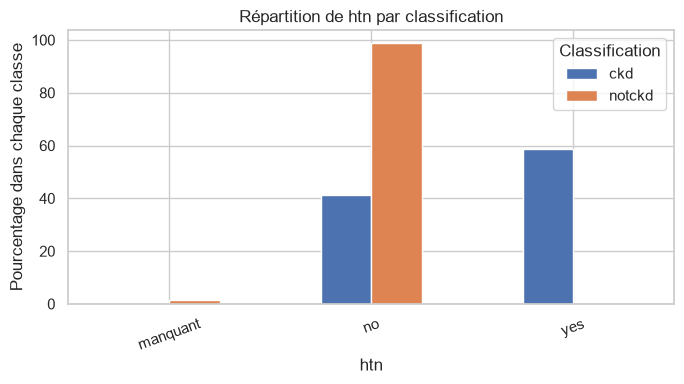

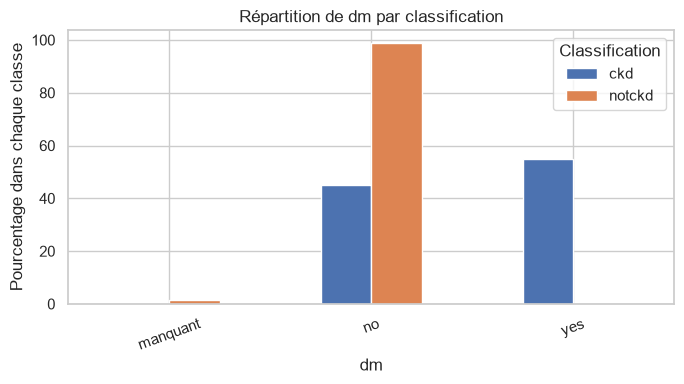

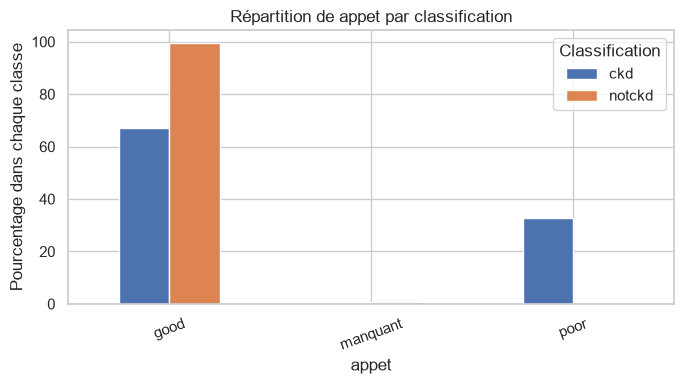

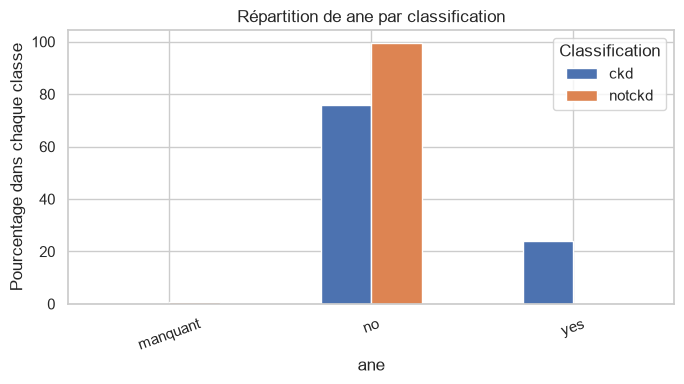

In [28]:
variables_cat_biv = [c for c in ["htn", "dm", "appet", "ane"] if c in df.columns]
for col in variables_cat_biv:
    tableau_prop = pd.crosstab(
        df[col].fillna("manquant"),
        df["classification"],
        normalize="columns"
    ) * 100
    tableau_prop.plot(kind="bar", figsize=(7, 4))
    plt.title(f"Répartition de {col} par classification")
    plt.xlabel(col)
    plt.ylabel("Pourcentage dans chaque classe")
    plt.xticks(rotation=20)
    plt.legend(title="Classification")
    plt.tight_layout()
    plt.show()

## 8. Corriger les tests multiples

Comme plusieurs variables sont testées, la probabilité d'obtenir au moins un résultat significatif par hasard augmente. On applique ici une correction Benjamini–Hochberg (contrôle du taux de fausses découvertes), si la version de SciPy le permet.

In [29]:
def ajouter_p_fdr(tableau, colonne_p):
    if tableau.empty or colonne_p not in tableau.columns:
        return tableau
    pvals = tableau[colonne_p].astype(float).to_numpy()
    try:
        p_corr = stats.false_discovery_control(pvals, method="bh")
    except AttributeError:
        warnings.warn(
            "Votre version de SciPy ne propose pas false_discovery_control. "
            "Mettez SciPy à jour ou interprétez les p-values brutes avec prudence."
        )
        return tableau
    resultat = tableau.copy()
    resultat["p_FDR_BH"] = p_corr
    resultat["Significatif_FDR_5%"] = resultat["p_FDR_BH"] < 0.05
    return resultat

if not comparaison_num.empty:
    print("Tests de Welch avec correction FDR :")
    display(ajouter_p_fdr(comparaison_num.reset_index(), "p_Welch").set_index("Variable").round(6))

if not comparaison_cat.empty:
    print("Tests du chi-deux avec correction FDR :")
    display(ajouter_p_fdr(comparaison_cat.reset_index(), "p_value").set_index("Variable").round(6))

Tests de Welch avec correction FDR :


,N_CKD,Moyenne_CKD,Mediane_CKD,N_notCKD,Moyenne_notCKD,Mediane_notCKD,p_Welch,p_Mann_Whitney,p_FDR_BH,Significatif_FDR_5%
Variable,,,,,,,,,,
age,242,54.541322,59.000,149,46.516779,46.00,0.000003,0.000000,0.000004,True
bp,240,79.625000,80.000,148,71.351351,70.00,0.000000,0.000000,0.000000,True
sg,208,1.013918,1.015,145,1.022414,1.02,0.000000,0.000000,0.000000,True
al,209,1.722488,2.000,145,0.000000,0.00,0.000000,0.000000,0.000000,True
su,206,0.766990,0.000,145,0.000000,0.00,0.000000,0.000000,0.000000,True
bgr,212,175.419811,143.500,144,107.722222,107.50,0.000000,0.000000,0.000000,True
bu,237,72.389030,53.000,144,32.798611,33.00,0.000000,0.000000,0.000000,True
sc,238,4.414916,2.250,145,0.868966,0.90,0.000000,0.000000,0.000000,True
sod,167,134.676647,136.000,145,141.731034,141.00,0.000000,0.000000,0.000000,True


Tests du chi-deux avec correction FDR :


,Chi2,ddl,p_value,Effectif_attendu_min,p_FDR_BH,Significatif_FDR_5%
Variable,,,,,,
htn,135.477426,1,0.000000,54.663317,0.000000,True
dm,121.260097,1,0.000000,50.944724,0.000000,True
cad,20.301804,1,0.000007,12.643216,0.000007,True
appet,59.521524,1,0.000000,30.621554,0.000000,True
pe,53.999720,1,0.000000,28.380952,0.000000,True
ane,40.231685,1,0.000000,22.406015,0.000000,True
pcc,25.694777,1,0.000000,15.484848,0.000000,True
ba,11.978282,1,0.000538,8.111111,0.000538,True
pc,69.229632,1,0.000000,31.988060,0.000000,True


## 9. Aide à l'interprétation et conclusion


In [30]:
print("Dimensions du jeu de données :", df.shape)
if "classification" in df.columns:
    print("\nEffectifs par classe (valeurs manquantes incluses) :")
    display(df["classification"].value_counts(dropna=False).to_frame("Effectif"))



Dimensions du jeu de données : (400, 26)

Effectifs par classe (valeurs manquantes incluses) :


,Effectif
classification,
ckd,250
notckd,150


# Conclusions de l'analyse descriptive univariée et bivariée

## 1. Résumé de l'analyse univariée

L'étude porte sur un groupe de 400 patients issus du fichier de données réelles kidney_clean.csv. Elle nous permet de dégager trois enseignements principaux :

- Répartition des patients :
  Le jeu de données comprend 62,5 % de patients atteints de la maladie rénale chronique (250 individus) et 37,5 % de sujets sains qui servent de groupe témoin (150 individus).

- Forme des distributions et choix des indicateurs :
  Les deux principaux marqueurs de la fonction rénale, la créatinine sérique (sc) et l'urée sanguine (bu), présentent des distributions très étirées vers la droite, avec quelques valeurs extrêmement fortes chez les patients gravement malades (jusqu'à 76 mg/dL pour la créatinine).
  Pour cette raison, la moyenne arithmétique (3,07 mg/dL pour la créatinine) est trompeuse. Il est beaucoup plus juste d'utiliser la médiane (1,30 mg/dL) et l'écart interquartile (IQR) pour décrire fidèlement la population.

- Gestion des données manquantes :
  On compte 1 015 valeurs manquantes dans le fichier, soit 10,6 % des 9 600 cellules des 24 variables explicatives.
  Ces manques touchent surtout les examens spécialisés comme les globules rouges dans les urines (rbc, 38 % de manques) ou le comptage des érythrocytes (rc, 32,75 % de manques). Ces manquants sont nettement plus fréquents chez les patients atteints de la maladie (par exemple rbc : 57,2 % contre 6,0 % chez les sujets sains) ; les causes ne sont pas établies.

---

## 2. Résumé de l'analyse bivariée (Facteurs clés et associations)

L'analyse bivariée montre des différences statistiques majeures entre les personnes malades et les sujets témoins (confirmées après correction des tests multiples pour 13 des 14 variables numériques, seul pot ne l'étant pas, et pour les 10 variables qualitatives) :

1. Pour les variables numériques (Tests de Welch et de Mann-Whitney) :
   - Créatinine sérique (sc) : La valeur médiane monte à 2,25 mg/dL chez les personnes malades, contre 0,90 mg/dL chez les sujets sains. C'est le marqueur sanguin le plus net de la dégradation des reins.
   - Hémoglobine (hemo) : On observe une baisse très importante du taux d'hémoglobine chez les malades (10,65 g/dL en moyenne, contre 15,19 g/dL chez les témoins), ce qui s'explique par le développement fréquent d'une anémie liée à la maladie rénale.
   - Albumine urinaire (al) : Tous les sujets témoins mesurés (145 sur 150) présentent une albumine strictement nulle (0,00), alors que les personnes malades affichent un score moyen de 1,72.

2. Pour les variables qualitatives (Test du Chi-deux) :
   - Antécédents médicaux majeurs : L'hypertension artérielle (htn) et le diabète (dm) sont les deux facteurs les plus marquants. Dans ce jeu de données, 100 % des patients hypertendus (147 sur 147) et 100 % des patients diabétiques (137 sur 137) font partie du groupe atteint de maladie rénale chronique.
   - Symptômes observés : Les œdèmes des membres inférieurs (pe), la perte d'appétit (appet) et l'anémie clinique (ane) apparaissent uniquement chez les patients malades.